<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/Experiment9__trigger_word_detection_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎙️ Trigger Word Detection with PyTorch

**A hands-on lesson**

Have you ever said *"Hey Siri"*, *"Alexa"* or *"OK Google"* and watched a device wake up? That is **trigger word detection** (also called *keyword spotting* or *wake-word detection*). In this notebook we will build a small version of it from scratch.

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain how raw audio is turned into something a neural network can learn from (**waveform → Mel-spectrogram**).
2. Build a PyTorch `Dataset` / `DataLoader` that reads `.wav` files from a folder.
3. Design and train a small **Convolutional Neural Network (CNN)** for binary classification (*trigger* vs *not trigger*).
4. Evaluate the model with accuracy, precision, recall and a confusion matrix.
5. **Test the trained model by uploading your own audio file**, including a sliding-window detector for longer recordings.

### 🧠 The big picture

```
 .wav file ──► resample to 16 kHz ──► fix length (1 s) ──► Mel-spectrogram ──► CNN ──► P(trigger)
```

### 📁 Required folder structure

Put your training audio in a folder called `data`, with **one sub-folder per class**:

```
data/
 ├── trigger/        <- recordings of your trigger word (e.g. "hey computer")
 │     ├── a1.wav
 │     └── a2.wav ...
 └── background/     <- anything else: other words, noise, silence, music...
       ├── b1.wav
       └── b2.wav ...
```

> **Rule:** the sub-folder named `trigger` is the positive class (label 1). Every other sub-folder is treated as "not trigger" (label 0).
> Tip: aim for at least 50–100 clips per class. More variety (different speakers, distances, noise) = a better model.

## 1️⃣ Setup

We use:
- **PyTorch** for the neural network,
- **torchaudio** for resampling and Mel-spectrograms,
- **soundfile** for reading `.wav` files,
- **matplotlib** for plots.

Uncomment the first line if you are running in a fresh environment (e.g. Google Colab already has torch and torchaudio).

In [ ]:
# !pip install torch torchaudio soundfile matplotlib numpy

import os, glob, random, math
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader

# Make results reproducible
SEED = 25
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Using device:", device)

PyTorch: 2.11.0+cpu
Using device: cpu


### ⚙️ Configuration

All the important constants.

| Setting | Meaning |
|---|---|
| `SAMPLE_RATE` | Every file is converted to this rate (16 kHz is standard for speech). |
| `CLIP_SECONDS` | Length of audio the model looks at. Shorter clips are padded, longer ones are cropped. |
| `N_MELS` | Number of Mel frequency bands (the "height" of the spectrogram image). |
| `EPOCHS` | How many full passes over the training data. |

In [ ]:
DATA_DIR      = "/content/drive/MyDrive/Colab Notebooks/trigger_data"
TRIGGER_CLASS = "trigger1"      # name of the folder that holds the trigger-word clips

SAMPLE_RATE   = 16000
CLIP_SECONDS  = 1.0
CLIP_SAMPLES  = int(SAMPLE_RATE * CLIP_SECONDS)

N_FFT         = 400            # 25 ms window
HOP_LENGTH    = 160            # 10 ms step
N_MELS        = 64

BATCH_SIZE    = 32
EPOCHS        = 20
LEARNING_RATE = 1e-3
VAL_SPLIT     = 0.2
MODEL_PATH    = "trigger_word_model.pt"

#### Mount the Drive to fetch data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Check the data

In [ ]:
has_data = os.path.isdir(DATA_DIR) and len(glob.glob(f"{DATA_DIR}/**/*.wav", recursive=True)) > 0
if not has_data:
    print(f"No wav files found in {os.getcwd(), DATA_DIR} ")
else:
    print("Found real data in 'data/'. Using it.")

Found real data in 'data/'. Using it.


#### Following Code is used to save Data File to be used later on

In [ ]:

#shutil.copytree(DATA_DIR, "/content/drive/MyDrive/trigger_data")
#shutil.copy(MODEL_PATH, "/content/drive/MyDrive/")

In [ ]:
# Scan the folder and build a list of (file_path, label)
samples = []
for class_dir in sorted(os.listdir(DATA_DIR)):
    full = os.path.join(DATA_DIR, class_dir)
    if not os.path.isdir(full):
        continue
    label = 1 if class_dir.lower() == TRIGGER_CLASS else 0
    files = glob.glob(os.path.join(full, "**", "*.wav"), recursive=True)
    print(f"{class_dir:<15} label={label}  files={len(files)}")
    samples += [(f, label) for f in files]

n_pos = sum(l for _, l in samples); n_neg = len(samples) - n_pos
print(f"\nTotal: {len(samples)}  |  trigger: {n_pos}  |  not trigger: {n_neg}")
assert n_pos > 0 and n_neg > 0, "You need at least one 'trigger' folder and one other folder with .wav files."

background      label=0  files=120
trigger1        label=1  files=13

Total: 133  |  trigger: 13  |  not trigger: 120


## 3️⃣ From sound to numbers

Computers see audio as a long list of numbers (the **waveform**): amplitude measured 16,000 times per second.

A neural network learns better from a **Mel-spectrogram**: an "image" of the sound where
- the x-axis is **time**,
- the y-axis is **frequency** (on the Mel scale, which mimics human hearing),
- the colour is **loudness** (in decibels).

Different words produce visibly different patterns, so a CNN (great at images!) can learn to tell them apart.

First, a helper that loads *any* wav file and standardises it: mono, 16 kHz, exactly 1 second, volume-normalised.

In [ ]:
def load_audio(path, sample_rate=SAMPLE_RATE):
    """Read a wav file -> mono float32 torch tensor at `sample_rate`. Shape: (num_samples,)"""
    data, sr = sf.read(path, dtype="float32", always_2d=True)   # (samples, channels)
    wav = torch.from_numpy(data.mean(axis=1))                   # stereo -> mono
    if sr != sample_rate:
        wav = torchaudio.functional.resample(wav, sr, sample_rate)
    return wav

def fix_length(wav, length=CLIP_SAMPLES):
    """Pad with zeros or crop so the clip has exactly `length` samples."""
    if len(wav) > length:
        return wav[:length]
    return F.pad(wav, (0, length - len(wav)))

def normalize(wav):
    """Scale so the loudest point is +-1 (makes quiet and loud recordings comparable)."""
    return wav / (wav.abs().max() + 1e-9)

### 👀 Let's look at one example of each class

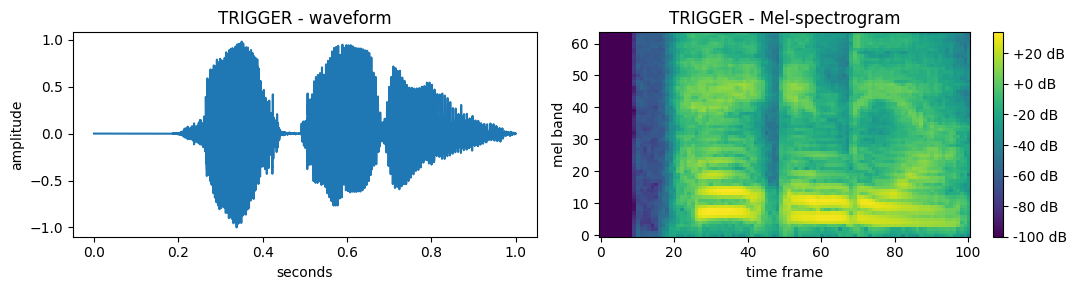

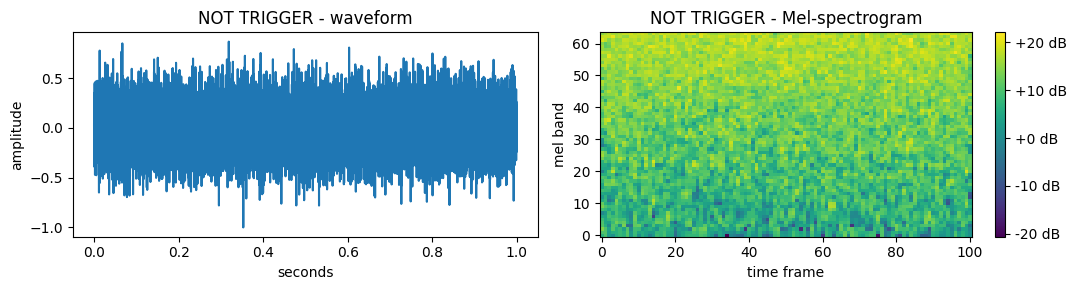

In [ ]:
mel_vis = torchaudio.transforms.MelSpectrogram(SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
to_db_vis = torchaudio.transforms.AmplitudeToDB()

def show_example(path, title):
    wav = normalize(fix_length(load_audio(path)))
    spec = to_db_vis(mel_vis(wav))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].plot(np.arange(len(wav)) / SAMPLE_RATE, wav.numpy()); ax[0].set_title(f"{title} - waveform")
    ax[0].set_xlabel("seconds"); ax[0].set_ylabel("amplitude")
    im = ax[1].imshow(spec.numpy(), origin="lower", aspect="auto"); ax[1].set_title(f"{title} - Mel-spectrogram")
    ax[1].set_xlabel("time frame"); ax[1].set_ylabel("mel band"); plt.colorbar(im, ax=ax[1], format="%+.0f dB")
    plt.tight_layout(); plt.show()

show_example(next(p for p, l in samples if l == 1), "TRIGGER")
show_example(next(p for p, l in samples if l == 0), "NOT TRIGGER")

## 4️⃣ PyTorch `Dataset` and `DataLoader`

A `Dataset` tells PyTorch **how to get one example**. A `DataLoader` then groups examples into **batches** and shuffles them.

We also add **data augmentation** (only for training). Because we rarely have enough recordings, we create slightly changed copies on the fly:
- **Random time shift:** the word may start at a different moment.
- **Random gain:** simulates the speaker being closer or farther.
- **Random noise:** simulates a noisy room.

This helps the model generalise instead of memorising.

In [ ]:
class TriggerWordDataset(Dataset):
    def __init__(self, items, augment=False):
        self.augment = augment
        # Pre-load everything into memory (fine for small datasets)
        self.waves  = [normalize(fix_length(load_audio(p))) for p, _ in items]
        self.labels = [float(l) for _, l in items]

    def __len__(self):
        return len(self.waves)

    def _augment(self, wav):
        # 1) random circular time shift up to +-0.15 s
        shift = random.randint(-int(0.15 * SAMPLE_RATE), int(0.15 * SAMPLE_RATE))
        wav = torch.roll(wav, shift)
        # 2) random gain
        wav = wav * random.uniform(0.6, 1.2)
        # 3) random background noise
        if random.random() < 0.5:
            wav = wav + torch.randn_like(wav) * random.uniform(0.0, 0.03)
        return wav

    def __getitem__(self, idx):
        wav = self.waves[idx]
        if self.augment:
            wav = self._augment(wav)
        return wav, torch.tensor(self.labels[idx])

# ----- stratified train / validation split (keeps class ratio in both sets)
rng = random.Random(SEED)
pos = [s for s in samples if s[1] == 1]; neg = [s for s in samples if s[1] == 0]
rng.shuffle(pos); rng.shuffle(neg)
n_val_p, n_val_n = max(1, int(len(pos) * VAL_SPLIT)), max(1, int(len(neg) * VAL_SPLIT))
val_items   = pos[:n_val_p] + neg[:n_val_n]
train_items = pos[n_val_p:] + neg[n_val_n:]

train_ds = TriggerWordDataset(train_items, augment=True)
val_ds   = TriggerWordDataset(val_items,   augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
print(f"Training clips: {len(train_ds)} | Validation clips: {len(val_ds)}")

Training clips: 107 | Validation clips: 26


## 5️⃣ The model

Our network has two parts, both inside a single `nn.Module`:

1. **Feature extractor** (no learning): waveform → Mel-spectrogram → log scale (dB) → normalise.
   Keeping this *inside* the model means training and testing always use identical preprocessing.
2. **CNN classifier** (learned): three blocks of `Conv → BatchNorm → ReLU → MaxPool` that detect increasingly complex patterns, followed by global pooling and a small fully-connected layer that outputs **one number** (a *logit*).

Passing the logit through a **sigmoid** gives a probability between 0 and 1: *"how likely is this the trigger word?"*

In [ ]:
class TriggerWordNet(nn.Module):
    def __init__(self):
        super().__init__()
        # --- fixed feature extraction
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
        self.to_db = torchaudio.transforms.AmplitudeToDB()

        # --- learnable CNN
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.cnn = nn.Sequential(block(1, 16), block(16, 32), block(32, 64))
        self.pool = nn.AdaptiveAvgPool2d((1, 1))      # -> (batch, 64, 1, 1) whatever the input size
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

    def features(self, wav):                           # wav: (batch, samples)
        x = self.to_db(self.mel(wav))                  # (batch, n_mels, frames)
        x = (x - x.mean(dim=(1, 2), keepdim=True)) / (x.std(dim=(1, 2), keepdim=True) + 1e-6)
        return x.unsqueeze(1)                          # add channel dim -> (batch, 1, n_mels, frames)

    def forward(self, wav):
        x = self.features(wav)
        x = self.pool(self.cnn(x))
        return self.head(x).squeeze(1)                 # (batch,) raw logits

model = TriggerWordNet().to(device)
print(model)
print("\nTrainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

TriggerWordNet(
  (mel): MelSpectrogram(
    (spectrogram): Spectrogram()
    (mel_scale): MelScale()
  )
  (to_db): AmplitudeToDB()
  (cnn): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride

## 6️⃣ Training

Key ideas for students:

- **Loss function:** `BCEWithLogitsLoss` is the standard loss for yes/no problems. It applies the sigmoid internally, which is numerically stable.
- **Class imbalance:** trigger clips are usually much rarer than background clips. We pass `pos_weight` so mistakes on the rare class are penalised more.
- **Optimizer:** Adam adapts the learning rate for every weight.
- **Validation:** after each epoch we test on clips the model has *never trained on*. If training accuracy rises but validation accuracy doesn't, we are **overfitting**.
- We **save the best model** (highest validation accuracy).

In [ ]:
pos_weight = torch.tensor([max(n_neg, 1) / max(n_pos, 1)], device=device)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer  = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for wav, y in loader:
            wav, y = wav.to(device), y.to(device)
            logits = model(wav)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct    += ((torch.sigmoid(logits) > 0.5).float() == y).sum().item()
            count      += len(y)
    return total_loss / count, correct / count

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = -1.0

for epoch in range(1, EPOCHS + 20):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    scheduler.step(va_loss)

    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)

    flag = ""
    if va_acc >= best_val_acc:
        best_val_acc = va_acc
        torch.save({"state_dict": model.state_dict(),
                    "config": dict(sample_rate=SAMPLE_RATE, clip_samples=CLIP_SAMPLES, n_fft=N_FFT,
                                   hop_length=HOP_LENGTH, n_mels=N_MELS)}, MODEL_PATH)
        flag = "  <- saved best model"
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f}{flag}")

print(f"\nBest validation accuracy: {best_val_acc:.3f}  (model saved to '{MODEL_PATH}')")

Epoch 01/20 | train loss 1.1965 acc 0.757 | val loss 1.1071 acc 0.385  <- saved best model
Epoch 02/20 | train loss 1.0240 acc 0.935 | val loss 1.1182 acc 0.077
Epoch 03/20 | train loss 0.8906 acc 0.963 | val loss 1.1467 acc 0.077
Epoch 04/20 | train loss 0.7407 acc 1.000 | val loss 1.1916 acc 0.077
Epoch 05/20 | train loss 0.6578 acc 1.000 | val loss 1.2181 acc 0.077
Epoch 06/20 | train loss 0.5978 acc 0.981 | val loss 1.1893 acc 0.077
Epoch 07/20 | train loss 0.6139 acc 0.991 | val loss 1.0494 acc 0.115
Epoch 08/20 | train loss 0.4751 acc 0.981 | val loss 0.7883 acc 0.385  <- saved best model
Epoch 09/20 | train loss 0.3814 acc 1.000 | val loss 0.7303 acc 0.423  <- saved best model
Epoch 10/20 | train loss 0.3445 acc 0.991 | val loss 0.7439 acc 0.423  <- saved best model
Epoch 11/20 | train loss 0.3135 acc 1.000 | val loss 0.6890 acc 0.423  <- saved best model
Epoch 12/20 | train loss 0.3334 acc 1.000 | val loss 0.3919 acc 0.923  <- saved best model
Epoch 13/20 | train loss 0.2300 ac

### 📈 Learning curves

What to look for:
- Both losses should go **down**.
- If the training curve keeps improving while the validation curve stalls or worsens → **overfitting** (try more data, more augmentation, more dropout).

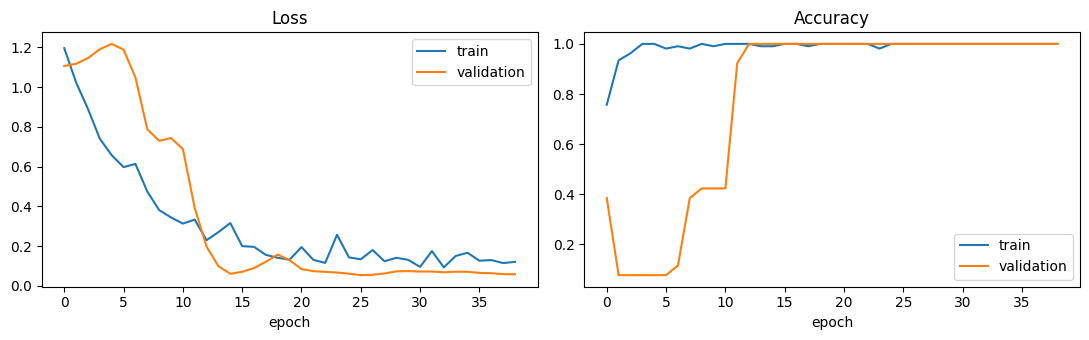

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7️⃣ Evaluation

Accuracy alone can be misleading (a model that always says "not trigger" can still look accurate if triggers are rare). So we also look at:

- **Precision:** of all the times the model said *"trigger!"*, how often was it right? (low precision = annoying false alarms)
- **Recall:** of all the real triggers, how many did the model catch? (low recall = the device ignores you)
- **Confusion matrix:** counts of every kind of correct / incorrect prediction.

Accuracy : 1.000
Precision: 1.000
Recall   : 1.000


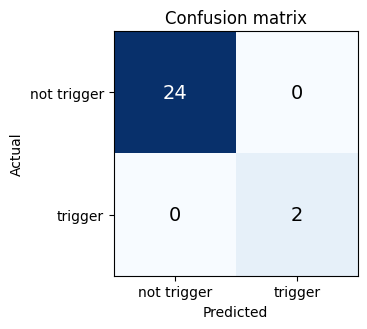

In [ ]:
# Load the best checkpoint and evaluate on the validation set
ckpt = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(ckpt["state_dict"]); model.eval()

all_pred, all_true = [], []
with torch.no_grad():
    for wav, y in val_loader:
        probs = torch.sigmoid(model(wav.to(device))).cpu()
        all_pred += (probs > 0.5).int().tolist(); all_true += y.int().tolist()

all_pred, all_true = np.array(all_pred), np.array(all_true)
tp = int(((all_pred == 1) & (all_true == 1)).sum()); tn = int(((all_pred == 0) & (all_true == 0)).sum())
fp = int(((all_pred == 1) & (all_true == 0)).sum()); fn = int(((all_pred == 0) & (all_true == 1)).sum())

precision = tp / (tp + fp) if tp + fp else 0.0
recall    = tp / (tp + fn) if tp + fn else 0.0
print(f"Accuracy : {(tp + tn) / len(all_true):.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")

cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["not trigger", "trigger"]); ax.set_xlabel("Predicted")
ax.set_yticks([0, 1]); ax.set_yticklabels(["not trigger", "trigger"]); ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Confusion matrix"); plt.tight_layout(); plt.show()

## 8️⃣ 🧪 Testing the model with your own audio file

Now the fun part! We will:

1. Rebuild the model and **load the saved weights** (just like a real application would).
2. Let you **upload a `.wav` file**.
3. Run it through the model and print the result.

### How does it handle long recordings?
The model was trained on **1-second clips**. If you upload a longer recording (e.g. a 10-second sentence), we use a **sliding window**: we slide a 1-second window along the audio in small steps, get a probability for each window, and report *when* the trigger word was heard. This is exactly how a real wake-word system listens to a continuous microphone stream.

In [ ]:
DETECTION_THRESHOLD = 0.5      # probability above which we say "trigger detected"
WINDOW_HOP_SECONDS  = 0.25     # how far the window moves each step

# ---- 1) Load the trained model from disk
ckpt = torch.load(MODEL_PATH, map_location=device)
test_model = TriggerWordNet().to(device)
test_model.load_state_dict(ckpt["state_dict"])
test_model.eval()
print("Model loaded from", MODEL_PATH)

# ---- 2) Prediction helpers
@torch.no_grad()
def predict_windows(path):
    """Returns (list of window start times in seconds, list of trigger probabilities)."""
    wav = load_audio(path)
    if len(wav) < CLIP_SAMPLES:                       # short clip -> pad to 1 s
        wav = fix_length(wav)
    hop = int(WINDOW_HOP_SECONDS * SAMPLE_RATE)
    starts = list(range(0, len(wav) - CLIP_SAMPLES + 1, hop))
    if starts[-1] + CLIP_SAMPLES < len(wav):          # make sure the tail is covered
        starts.append(len(wav) - CLIP_SAMPLES)
    batch = torch.stack([normalize(wav[s:s + CLIP_SAMPLES]) for s in starts]).to(device)
    probs = torch.sigmoid(test_model(batch)).cpu().numpy()
    return [s / SAMPLE_RATE for s in starts], probs

def test_audio_file(path):
    times, probs = predict_windows(path)
    best = int(np.argmax(probs))
    detected = probs[best] >= DETECTION_THRESHOLD

    print("=" * 55)
    print(f"File       : {os.path.basename(path)}")
    print(f"Duration   : {len(load_audio(path)) / SAMPLE_RATE:.2f} s")
    print(f"Max prob   : {probs[best]:.3f}  (window starting at {times[best]:.2f} s)")
    if detected:
        print("RESULT     : ✅ TRIGGER WORD DETECTED")
    else:
        print("RESULT     : ❌ Trigger word NOT detected")
    print("=" * 55)

    # Visualise
    wav = load_audio(path)
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    ax[0].plot(np.arange(len(wav)) / SAMPLE_RATE, wav.numpy(), lw=0.6)
    ax[0].set_title("Uploaded audio"); ax[0].set_ylabel("amplitude")
    centers = [t + CLIP_SECONDS / 2 for t in times]
    ax[1].plot(centers, probs, marker="o")
    ax[1].axhline(DETECTION_THRESHOLD, color="red", ls="--", label="threshold")
    ax[1].set_ylim(-0.05, 1.05); ax[1].set_ylabel("P(trigger)"); ax[1].set_xlabel("time (s)")
    ax[1].set_title("Model confidence over time"); ax[1].legend()
    plt.tight_layout(); plt.show()
    return detected

Model loaded from trigger_word_model.pt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 📤 Upload a file and test it

- **In Google Colab:** a file picker will appear. Choose your `.wav` file.
- **In Jupyter / VS Code / local Python:** you will be asked to type the path to a `.wav` file instead (e.g. `my_test.wav`).

You can run this cell **as many times as you like** with different recordings.

Saving HeyIndia.wav to HeyIndia.wav
File       : HeyIndia.wav
Duration   : 2.97 s
Max prob   : 0.978  (window starting at 0.75 s)
RESULT     : ✅ TRIGGER WORD DETECTED


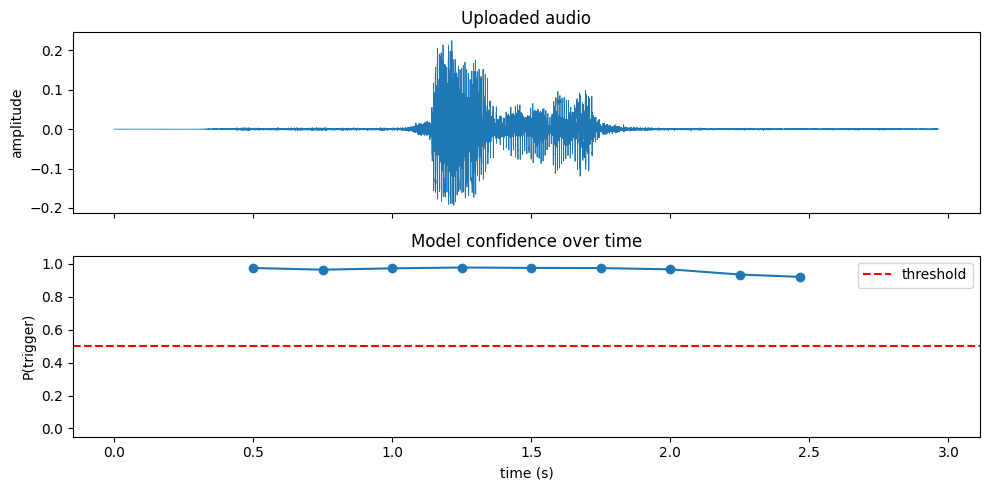

In [ ]:
def get_audio_path():
    """Ask the user for an audio file. Works in Google Colab (upload dialog) and locally (type a path)."""
    try:
        from google.colab import files          # only exists in Colab
        uploaded = files.upload()
        if not uploaded:
            return None
        name = next(iter(uploaded))
        return name                              # Colab saves the upload in the current folder
    except ImportError:
        path = input("Enter the path to a .wav file (e.g. data/trigger/demo_trigger_000.wav): ").strip().strip('"')
        return path or None

audio_path = get_audio_path()
if audio_path and os.path.exists(audio_path):
    test_audio_file(audio_path)
else:
    print("No valid file provided. Re-run this cell and choose a .wav file.")

### 🔊 (Optional) Listen to the file you tested

In [ ]:
from IPython.display import Audio, display
if audio_path and os.path.exists(audio_path):
    display(Audio(audio_path))